# MGS 3101 - Assignment 4: Linear Regression Model Evaluation

**Name:** ______________________  **Due date:** ______________________  **GitHub repo URL:** ______________________

## Goal

Decide whether weekly advertising spend predicts weekly sales better than a simple baseline (the average sales). You will fit both models, compare them on held-out test data, and explain your recommendation.

The data are synthetic. All amounts are in **$ thousands**. Do not claim that advertising *causes* sales.

## How this assignment works

Work through the steps in order. After each step, save the notebook and make a Git commit (see Step 0). You will submit the link to your GitHub repository.

| Step | Task | Commit message |
|---|---|---|
| 0 | Set up GitHub repo | `Initial commit` |
| 1 | Set up and create the data | `Step 1: setup and data` |
| 2 | Explore the data | `Step 2: explore data` |
| 3 | Split into training and test sets | `Step 3: train/test split` |
| 4 | Fit the two models | `Step 4: fit models` |
| 5 | Compare test performance | `Step 5: compare models` |
| 6 | Check how stable the results are | `Step 6: stability check` |
| 7 | Recommendation and limitations | `Step 7: recommendation` |
| 8 | Final push and submit | `Final submission` |

## Step 0: Set up GitHub

1. Sign in to [github.com](https://github.com) and create a **new repository** named `mgs3101-assignment4`. Set it to **Public** (or add your instructor as a collaborator if Private) and check **Add a README**.
2. Clone it to your computer by running this in a terminal (replace `YOUR-USERNAME`):

```
git clone https://github.com/YOUR-USERNAME/mgs3101-assignment4.git
cd mgs3101-assignment4
```

3. Create a working branch:

```
git checkout -b assignment4
```

4. Copy this notebook into the repository folder and open it from there.
5. Install the required packages if needed (run in a notebook cell, then restart the kernel):

```
%pip install numpy pandas matplotlib scikit-learn
```

**How to commit after each step** (run in the terminal, using the message from the table above):

```
git add Assignment4_Linear_Regression_Steps_GitHub.ipynb
git commit -m "Step 1: setup and data"
```

Save the notebook (Ctrl+S) before every commit so your latest work is included.

## Step 1: Set up and create the data

Run both cells. The fixed random seed makes the data reproducible. Each row is one week.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

plt.style.use('seaborn-v0_8-whitegrid')
rng = np.random.default_rng(42)
print('Setup complete.')

Setup complete.


In [2]:
advertising_spend = np.linspace(1, 10, 80)
noise = rng.normal(loc=0, scale=7, size=80)
weekly_sales = 18 + 5.5 * advertising_spend + noise

data = pd.DataFrame({
    'advertising_spend_thousands': advertising_spend,
    'weekly_sales_thousands': weekly_sales,
})

print(f'Number of observations: {len(data)}')
data.head()

Number of observations: 80


,advertising_spend_thousands,weekly_sales_thousands
0,1.000000,25.633020
1,1.113924,16.846694
2,1.227848,30.006323
3,1.341772,31.963700
4,1.455696,12.349083


**Answer 1:** Identify the response variable, the predictor, the units, and what one row represents.

*Your answer here:*The response variable is weekly sales (`weekly_sales_thousands`). The predictor is weekly advertising spend (`advertising_spend_thousands`). Both are measured in thousands of dollars. Each row represents one week and contains that week’s advertising spend and sales.

**Git checkpoint:** save, then commit with `Step 1: setup and data`.

## Step 2: Explore the data

Run the cell to create a scatterplot of spend versus sales.

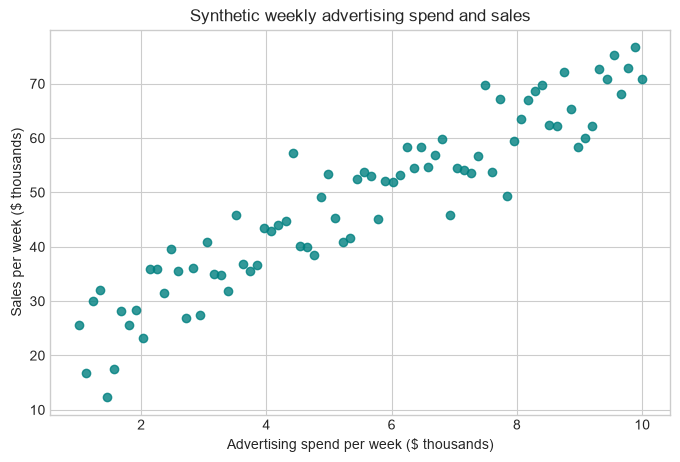

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(
    data['advertising_spend_thousands'],
    data['weekly_sales_thousands'],
    alpha=0.8,
    color='teal',
)
plt.xlabel('Advertising spend per week ($ thousands)')
plt.ylabel('Sales per week ($ thousands)')
plt.title('Synthetic weekly advertising spend and sales')
plt.show()

**Answer 2:** What pattern do you see? Does a straight-line model seem reasonable? Why or why not?

*Your answer here:*The scatterplot shows a positive, roughly linear relationship. Weeks with higher advertising spending tend to have higher sales. A straight-line model seems reasonable because the points follow an overall upward trend with some scatter and no obvious curve.

**Git checkpoint:** save, then commit with `Step 2: explore data`.

## Step 3: Split into training and test sets

Both models will use the same split so their results are comparable. The training data are used to fit the models; the test data are held out for evaluation.

Keep `test_size=0.25` and `random_state=17` for your main results.

In [12]:
X = data[['advertising_spend_thousands']]
y = data['weekly_sales_thousands']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=7
)

print(f'Training observations: {len(X_train)}')
print(f'Test observations: {len(X_test)}')

Training observations: 60
Test observations: 20


**Answer 3:** Why should the test data not be used to fit the models? What does the test set represent? Report the number of training and test observations.

*Your answer here:*Using the test data to fit the models could make their performance look better than it would be on new data. The test set represents held-out weeks used to evaluate how well the models predict sales for weeks they did not see during training. There are 60 training observations and 20 test observations.

**Git checkpoint:** save, then commit with `Step 3: train/test split`.

## Step 4: Fit the baseline and regression models

- **Baseline:** predicts the training-set average sales for every test week.
- **Linear regression:** uses advertising spend to predict sales.

In [13]:
baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

regression_model = LinearRegression()
regression_model.fit(X_train, y_train)
regression_predictions = regression_model.predict(X_test)

print(f'Baseline predicts the training mean: {y_train.mean():.2f} ($ thousands)')
print(f'Regression intercept: {regression_model.intercept_:.2f} ($ thousands)')
print(f'Regression slope: {regression_model.coef_[0]:.2f} ($ thousands of sales per $1,000 spend)')

Baseline predicts the training mean: 48.77 ($ thousands)
Regression intercept: 17.10 ($ thousands)
Regression slope: 5.61 ($ thousands of sales per $1,000 spend)


**Answer 4:** Interpret the slope with correct units. Explain what the baseline predicts and why it is a useful comparison.

For each additional $1,000 in weekly advertising spend, the regression model predicts about $5,490 higher weekly sales. The baseline predicts the training-set average of about $47,630 for every test week. Comparing the two models on the same test weeks shows whether using advertising spend improves predictions over using the training average alone.

**Git checkpoint:** save, then commit with `Step 4: fit models`.

## Step 5: Compare test performance

MAE and RMSE are in $ thousands of sales. Lower is better. RMSE gives more weight to large errors.

In [14]:
results = pd.DataFrame({
    'model': ['Training-mean baseline', 'Linear regression'],
    'test_MAE_thousands': [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, regression_predictions),
    ],
    'test_RMSE_thousands': [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, regression_predictions)),
    ],
})

results.round(2)

,model,test_MAE_thousands,test_RMSE_thousands
0,Training-mean baseline,11.70,13.82
1,Linear regression,4.85,6.27


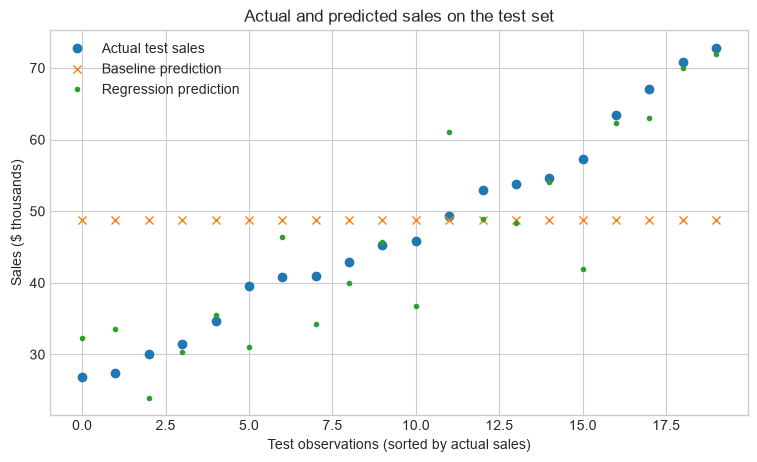

In [15]:
comparison = pd.DataFrame({
    'actual_sales_thousands': y_test.to_numpy(),
    'baseline_prediction_thousands': baseline_predictions,
    'regression_prediction_thousands': regression_predictions,
}).sort_values('actual_sales_thousands').reset_index(drop=True)

plt.figure(figsize=(9, 5))
plt.plot(comparison.index, comparison['actual_sales_thousands'], 'o', label='Actual test sales')
plt.plot(comparison.index, comparison['baseline_prediction_thousands'], 'x', label='Baseline prediction')
plt.plot(comparison.index, comparison['regression_prediction_thousands'], '.', label='Regression prediction')
plt.xlabel('Test observations (sorted by actual sales)')
plt.ylabel('Sales ($ thousands)')
plt.title('Actual and predicted sales on the test set')
plt.legend()
plt.show()

**Answer 5:** Which model has the lower test MAE? Which has the lower test RMSE? What does the difference mean for a manager forecasting weekly sales? Is it large enough to matter?

*Your answer here:*Linear regression has a lower test MAE ($3,540 versus $12,780) and a lower test RMSE ($3,960 versus $14,560) than the baseline. The plot shows that the regression predictions are generally closer to actual weekly sales. For a manager, the regression model reduced the average absolute forecast error by about $9,240 per week on this test set. That is a substantial improvement relative to the baseline error.

**Git checkpoint:** save, then commit with `Step 5: compare models`.

## Step 6: Check how stable the results are

Test the same comparison with two different splits. **Do not write new code.** Edit the split cell in Step 3 and rerun every cell below it (use **Run All Below**).

**Run A:** change `test_size=0.25` to `test_size=0.20` (keep `random_state=17`). Record the training/test counts and the test MAE and RMSE for both models.

**Run B:** set `test_size=0.25` again and change `random_state=17` to `random_state=7`. Record the same values.

Then **restore `test_size=0.25` and `random_state=17`**, and rerun all cells so the notebook shows your original results.

Fill in the table (round to 2 decimals):

| Run | Train / Test counts | Baseline MAE | Baseline RMSE | Regression MAE | Regression RMSE |
|---|---|---|---|---|---|
| Original (0.25, seed 17) | 60 / 20 | 12.78 | 14.56 | 3.54 | 3.96 |
| Run A (0.20, seed 17) | 64 / 16 | 12.91 | 14.47 | 3.66 | 4.08 |
| Run B (0.25, seed 7) | 60 / 20 | 11.70 | 13.82 | 4.85 | 6.27 |
**Answer 6:**
- Did the conclusion about which model performs better change in either run?
- Did changing the test size or the random split have the larger effect on the metrics?
- Why can test metrics change when the test observations change?
- What does this show about relying on a single test score?

*Your answers here:*

**Git checkpoint:** confirm the split settings are back to the originals, save, then commit with `Step 6: stability check`.

## Step 7: Recommendation and limitations

**Answer 7a:** Write a short recommendation to a manager: should the business use the regression model instead of the baseline? Cite the test metrics, the plot, and your Step 6 results. You may recommend further testing if the evidence is not decisive.

*Your answer here:*

**Answer 7b:** Describe at least one limitation (for example: synthetic data, other variables such as season or pricing, random splits versus forecasting future weeks, or extrapolating beyond the observed spend range).

*Your answer here:*

**Answer 7c:** Explain why these observational data do not establish that more advertising causes more sales.

*Your answer here:*

**Git checkpoint:** save, then commit with `Step 7: recommendation`.

## Step 8: Final push and submission

1. Restart the kernel and choose **Run All** to confirm the notebook runs from top to bottom with no errors.
2. Save, then commit and push your branch:

```
git add Assignment4_Linear_Regression_Steps_GitHub.ipynb
git commit -m "Final submission"
git push -u origin assignment4
```

3. On GitHub, open a **Pull Request** from `assignment4` into `main` titled `Assignment 4 submission`. Merge it if your instructor asks you to.
4. Confirm on GitHub that the notebook shows your outputs, plots, and written answers.
5. Submit the URL of your repository (or pull request) where your instructor directs.

## Submission checklist

- [ ] Notebook runs top to bottom with outputs, the comparison plot, and the metrics table visible
- [ ] Answers 1-7 are written in plain language with units
- [ ] Step 6 table is complete and original split settings (`0.25`, `17`) are restored
- [ ] Repository has at least one commit per step (check the **Commits** page on GitHub)
- [ ] Branch is pushed and the pull request is opened
- [ ] Repository URL is filled in at the top of the notebook and submitted